# 02 · Ingeniería de características a nivel de cliente

**Objetivo:** pasar de transacciones a una fila por cliente, elegir un conjunto de variables
**no redundante** para el clustering, decidir su transformación y escalado, el tratamiento de los
clientes extremos (mayoristas) y construir el **baseline RFM por quintiles** con el que se compararán
los modelos.

Entrada: `data/processed/transacciones_limpias.parquet` y `devoluciones.parquet` (notebook 01).
Toda la lógica está en `src/segmentacion/features.py` y `evaluacion.py`; aquí solo se invoca y narra.

> Los clusterings de este notebook son **de prueba** (K-Means con k = 3..6) y sirven solo para comparar
> alternativas de preprocesamiento. El modelado formal es el del notebook 03.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import RobustScaler, StandardScaler

from segmentacion import config
from segmentacion.evaluacion import ari, diagnostico_kmeans
from segmentacion.features import (PERCENTILES_WINSOR, VARIABLES_CLUSTERING, VARIABLES_PERFIL,
                                   calcular_variables_cliente, calcular_vif, construir_preprocesador,
                                   devoluciones_computables, fecha_referencia, segmentar_rfm_quintiles)
from segmentacion.visualizacion import COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO, estilo, guardar_figura

estilo()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ventas = pd.read_parquet(config.PARQUET_LIMPIO)
devoluciones = pd.read_parquet(config.PARQUET_DEVOLUCIONES)
referencia = fecha_referencia(ventas)
print(f"Ventas limpias: {len(ventas):,} líneas · {ventas['CustomerID'].nunique():,} clientes")
print(f"Última transacción: {ventas['InvoiceDate'].max()} → fecha de referencia: {referencia.date()}")

Ventas limpias: 388,422 líneas · 4,324 clientes
Última transacción: 2011-12-09 12:50:00 → fecha de referencia: 2011-12-10


## 1. Variables por cliente

| Variable | Definición | Unidad |
|---|---|---|
| `recency` | días entre la fecha de referencia y el día de la última compra | días |
| `frequency` | facturas distintas | facturas |
| `monetary` | gasto total en ventas limpias | £ |
| `ticket_promedio` | monetary / frequency | £ por factura |
| `productos_distintos` | StockCode distintos comprados | productos |
| `antiguedad` | días entre la primera compra y la fecha de referencia | días |
| `dias_entre_compras` | (última − primera compra) / (frequency − 1) | días |
| `unidades_por_factura` | unidades totales / frequency | unidades |
| `tasa_devoluciones` | importe devuelto computable / importe comprado, recortada a [0, 1] (ver `features.py`) | proporción |
| `pais` | país con más facturas del cliente | — |

In [2]:
clientes = calcular_variables_cliente(ventas, devoluciones, referencia)
print(f"Tabla de clientes: {clientes.shape[0]:,} filas × {clientes.shape[1]} columnas")
clientes.head()

Tabla de clientes: 4,324 filas × 10 columnas


,recency,frequency,monetary,ticket_promedio,productos_distintos,antiguedad,dias_entre_compras,unidades_por_factura,tasa_devoluciones,pais
CustomerID,,,,,,,,,,
12347,3,7,"4,310.000",615.714,103,368,60.840,351.143,0.000,Iceland
12348,76,4,"1,437.240",359.310,21,359,94.251,583.000,0.000,Finland
12349,19,1,"1,457.550","1,457.550",72,19,NaN,630.000,0.000,Italy
12350,311,1,294.400,294.400,16,311,NaN,196.000,0.000,Norway
12352,37,6,"1,265.410",210.902,57,297,52.017,77.167,0.000,Norway


In [3]:
clientes.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,25%,50%,75%,99%,max
recency,"4,324.000",93.351,100.259,1.000,18.000,51.000,144.000,369.000,374.000
frequency,"4,324.000",4.227,7.570,1.000,1.000,2.000,5.000,29.770,203.000
monetary,"4,324.000","1,922.352","8,311.967",2.900,301.312,656.000,"1,615.045","17,235.087","278,778.020"
ticket_promedio,"4,324.000",371.980,452.148,2.900,174.970,286.861,422.716,"1,909.720","12,425.450"
productos_distintos,"4,324.000",61.246,84.964,1.000,16.000,35.000,77.000,352.000,"1,756.000"
antiguedad,"4,324.000",223.990,117.769,1.000,114.000,249.500,327.000,374.000,374.000
dias_entre_compras,"2,821.000",73.449,65.617,0.000,30.350,54.551,93.356,331.272,365.982
unidades_por_factura,"4,324.000",227.359,306.173,1.000,92.000,160.000,270.125,"1,344.480","7,824.000"
tasa_devoluciones,"4,324.000",0.006,0.024,0.000,0.000,0.000,0.001,0.105,0.645


**Hallazgos — tabla de clientes**

- La tabla tiene **4.324 clientes** y la fecha de referencia es el **10-12-2011** (última transacción: 09-12-2011 12:50).
  La compra más reciente tiene recency = 1.
- La mediana de cliente compró hace 51 días, en 2 facturas, gastó 656 £ con un ticket de 286,86 £ y llevó 35
  productos distintos. Las colas son muy largas: hasta 203 facturas, 278.778,02 £ de gasto y 1.756 productos.
- `dias_entre_compras` solo tiene 2.821 valores: falta en el resto (ver sección 2).

## 2. Días promedio entre compras: clientes con una sola compra

Con una sola factura no hay intervalo entre compras: la variable **no está definida**. Se cuantifica
y se comparan cuatro alternativas.

In [4]:
una_compra = clientes["frequency"].eq(1)
sin_definir = clientes["dias_entre_compras"].isna()
print(f"Clientes con una sola factura: {una_compra.sum():,} ({100 * una_compra.mean():.1f} %)")
print(f"dias_entre_compras sin definir: {sin_definir.sum():,} · coincide exactamente con frequency = 1: {(una_compra == sin_definir).all()}")
print(f"Ingresos de esos clientes: {100 * clientes.loc[una_compra, 'monetary'].sum() / clientes['monetary'].sum():.1f} % del total")
clientes.loc[una_compra, ["recency", "monetary", "productos_distintos"]].describe().T

Clientes con una sola factura: 1,503 (34.8 %)
dias_entre_compras sin definir: 1,503 · coincide exactamente con frequency = 1: True
Ingresos de esos clientes: 6.5 % del total


,count,mean,std,min,25%,50%,75%,max
recency,"1,503.000",157.627,115.667,1.000,53.000,134.000,262.000,374.000
monetary,"1,503.000",360.402,491.137,2.900,150.325,252.730,394.410,"9,341.260"
productos_distintos,"1,503.000",21.703,22.051,1.000,8.000,16.000,28.000,251.000


**Alternativa A — imputar con la mediana.**

Mediana (clientes con ≥ 2 facturas): 54.55 días
Clientes con exactamente ese valor tras imputar: 1,504 (34.8 %)


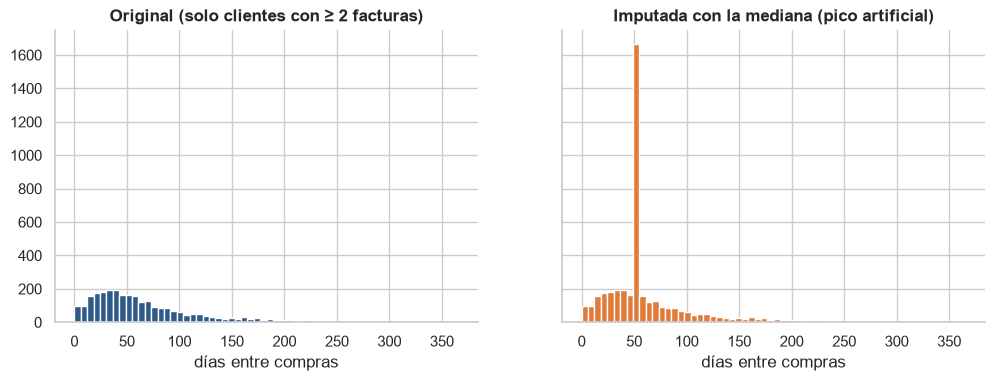

In [5]:
mediana = clientes["dias_entre_compras"].median()
imputada_mediana = clientes["dias_entre_compras"].fillna(mediana)
print(f"Mediana (clientes con ≥ 2 facturas): {mediana:.2f} días")
print(f"Clientes con exactamente ese valor tras imputar: {(imputada_mediana == mediana).sum():,} "
      f"({100 * (imputada_mediana == mediana).mean():.1f} %)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
axes[0].hist(clientes["dias_entre_compras"].dropna(), bins=60, color=COLOR_PRINCIPAL)
axes[0].set_title("Original (solo clientes con ≥ 2 facturas)")
axes[1].hist(imputada_mediana, bins=60, color=COLOR_SECUNDARIO)
axes[1].set_title("Imputada con la mediana (pico artificial)")
for ax in axes:
    ax.set_xlabel("días entre compras")
guardar_figura(fig, "02_imputacion_dias_entre_compras")
plt.show()

**Alternativa B — imputar con el tiempo transcurrido desde la compra (recency).**

In [6]:
imputada_recency = clientes["dias_entre_compras"].fillna(clientes["recency"])
print("Correlación de Spearman con recency, solo en los imputados:",
      round(imputada_recency[una_compra].corr(clientes.loc[una_compra, "recency"], method="spearman"), 3))
print("Correlación de Spearman con recency, en todos:",
      round(imputada_recency.corr(clientes["recency"], method="spearman"), 3),
      "· sin imputar (solo ≥ 2 facturas):",
      round(clientes["dias_entre_compras"].corr(clientes["recency"], method="spearman"), 3))

Correlación de Spearman con recency, solo en los imputados: 1.0
Correlación de Spearman con recency, en todos: 0.543 · sin imputar (solo ≥ 2 facturas): 0.189


**Alternativa C — variable indicadora `una_compra`.**

In [7]:
pd.crosstab(clientes['frequency'].eq(1).rename('frequency = 1'), una_compra.rename('una_compra'))

una_compra,False,True
frequency = 1,,
False,2821,0
True,0,1503


**Alternativa D — excluirla del clustering y usarla solo para perfilar.** ¿Cuánta información comparte con las variables que sí entran?

In [8]:
con_intervalo = clientes[~una_compra]
con_intervalo[["dias_entre_compras", "frequency", "recency", "antiguedad", "monetary"]].corr("spearman")["dias_entre_compras"].to_frame("spearman")

,spearman
dias_entre_compras,1.000
frequency,-0.453
recency,0.189
antiguedad,0.203
monetary,-0.342


**Hallazgos — días entre compras**

- **1.503 clientes (34,8 %) tienen una sola factura**, y son exactamente los que no tienen `dias_entre_compras`.
  Suponen el 6,5 % de los ingresos, con una mediana de 252,73 £ de gasto y 134 días desde su compra.

| Alternativa | Qué pasa con los datos | Problema |
|---|---|---|
| **A. Imputar con la mediana** (54,55 días) | 1.504 clientes (34,8 %) quedan con exactamente el mismo valor | Crea un pico artificial y atribuye un ritmo de compra "típico" a quien nunca repitió. Ese grupo pesaría en los clusters por un valor inventado |
| **B. Imputar con la recency** | En los imputados la correlación con recency es **1,0**; en el total sube de 0,189 a 0,543 | Duplica una variable que ya entra en el clustering y mezcla "no ha vuelto" con "compra lento" |
| **C. Indicadora `una_compra`** | Coincide **exactamente** con `frequency = 1` (tabla cruzada sin errores) | No aporta información nueva, y una variable binaria distorsiona las distancias euclídeas de K-Means |
| **D. Excluir del clustering y usar solo para perfilar** | Entre los clientes con ≥ 2 facturas correlaciona −0,453 con frequency | Se pierde algo de información sobre el ritmo, pero la parte principal ya la recoge frequency |

**Decisión: D.** Ninguna imputación es neutral: A y B inventan un dato que define a un tercio de los clientes, y C
repite frequency. La variable se conserva para **perfilar** los segmentos de clientes recurrentes.

## 3. Correlaciones y redundancia

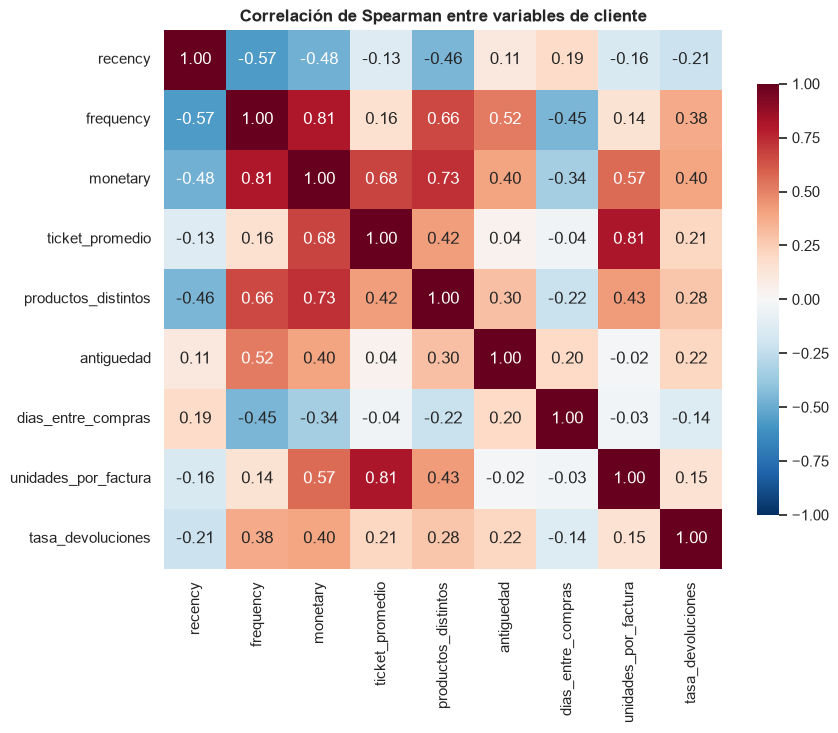

,var_1,var_2,spearman
11,frequency,monetary,0.808
34,ticket_promedio,unidades_por_factura,0.814


In [9]:
numericas = clientes.drop(columns="pais")
corr = numericas.corr("spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlación de Spearman entre variables de cliente")
guardar_figura(fig, "02_correlaciones")
plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares[pares["spearman"].abs() >= 0.8]

`monetary` es por definición `frequency × ticket_promedio`. En escala logarítmica eso es una suma
exacta: `log(monetary) = log(frequency) + log(ticket_promedio)`. Se comprueba:

In [10]:
suma_logs = np.log(clientes["frequency"]) + np.log(clientes["ticket_promedio"])
print("Diferencia máxima entre log(monetary) y log(frequency) + log(ticket):",
      float((np.log(clientes["monetary"]) - suma_logs).abs().max()))

Diferencia máxima entre log(monetary) y log(frequency) + log(ticket): 1.7763568394002505e-15


In [11]:
en_log = np.log1p(numericas.drop(columns="dias_entre_compras"))
print("VIF de todas las variables (en log1p):")
calcular_vif(en_log).to_frame()

VIF de todas las variables (en log1p):


,vif
recency,2.799
frequency,92.146
monetary,198.662
ticket_promedio,69.508
productos_distintos,2.194
antiguedad,2.397
unidades_por_factura,3.280
tasa_devoluciones,1.021


In [12]:
candidatos = {
    "R, F, M": ["recency", "frequency", "monetary"],
    "R, F, M, productos": ["recency", "frequency", "monetary", "productos_distintos"],
    "R, F, M, unidades/factura": ["recency", "frequency", "monetary", "unidades_por_factura"],
    "R, F, ticket, productos": ["recency", "frequency", "ticket_promedio", "productos_distintos"],
    "R, F, ticket, productos, antigüedad": ["recency", "frequency", "ticket_promedio", "productos_distintos", "antiguedad"],
}
filas = []
for nombre, vars_ in candidatos.items():
    vif = calcular_vif(en_log[vars_])
    c = numericas[vars_].corr("spearman").where(np.triu(np.ones((len(vars_),) * 2, dtype=bool), k=1))
    filas.append({"conjunto": nombre, "vif_max": vif.max(), "|spearman|_max": c.abs().max().max()})
pd.DataFrame(filas).set_index("conjunto")

,vif_max,|spearman|_max
conjunto,,
"R, F, M",3.332,0.808
"R, F, M, productos",3.643,0.808
"R, F, M, unidades/factura",8.732,0.808
"R, F, ticket, productos",2.018,0.656
"R, F, ticket, productos, antigüedad",3.442,0.656


In [13]:
solo_una = clientes[una_compra]
print("Clientes con una factura en los que antiguedad == recency:",
      f"{(solo_una['antiguedad'] == solo_una['recency']).mean():.0%}")
print("Variables elegidas para el clustering:", VARIABLES_CLUSTERING)
print("Variables solo para perfilar:", VARIABLES_PERFIL)

Clientes con una factura en los que antiguedad == recency: 100%
Variables elegidas para el clustering: ['recency', 'frequency', 'ticket_promedio', 'productos_distintos']
Variables solo para perfilar: ['monetary', 'antiguedad', 'dias_entre_compras', 'unidades_por_factura', 'tasa_devoluciones', 'pais']


**Hallazgos — correlaciones y selección de variables**

- **Redundancia exacta:** `log(monetary) = log(frequency) + log(ticket_promedio)` con un error máximo de 1,8·10⁻¹⁵
  (precisión de máquina). Con las tres variables juntas el VIF se dispara (frequency 92, monetary 199, ticket 70):
  una de ellas sobra.
- **Pares con |ρ| ≥ 0,8:** frequency–monetary (0,808) y ticket_promedio–unidades_por_factura (0,814).
- **Conjuntos comparados:** el único que cumple a la vez VIF < 5 y |ρ| < 0,8 en todos sus pares es
  **R, F, ticket, productos**, con VIF máximo 2,018 y |ρ| máximo 0,656. Los que llevan monetary junto a frequency
  rompen el umbral de correlación (0,808).

**Decisión — variables de clustering: `recency`, `frequency`, `ticket_promedio`, `productos_distintos`.**
- `monetary` no se pierde: es frequency × ticket, así que queda recogida, y además separa dos conductas que la
  suma confunde (comprar a menudo frente a comprar mucho en cada pedido). Se usa para perfilar y en el baseline.
- `unidades_por_factura` se descarta por redundante con el ticket (0,814).
- `antiguedad` no entra: en los clientes de una sola factura es **igual a la recency (100 %)**, es decir, en un
  tercio de la base duplica otra variable. Además empeora con log (asimetría de −0,37 a −1,52, sección 4). Queda para perfilar.
- `tasa_devoluciones` se analiza aparte en la sección 7.

## 4. Asimetría y transformación logarítmica

In [14]:
asimetria = pd.DataFrame({"original": numericas.skew(), "log1p": np.log1p(numericas).skew()})
asimetria.loc[VARIABLES_CLUSTERING + ["monetary", "antiguedad", "tasa_devoluciones"]]

,original,log1p
recency,1.241,-0.326
frequency,11.842,1.217
ticket_promedio,10.039,-0.000
productos_distintos,6.832,-0.246
monetary,21.502,0.350
antiguedad,-0.368,-1.524
tasa_devoluciones,10.450,8.717


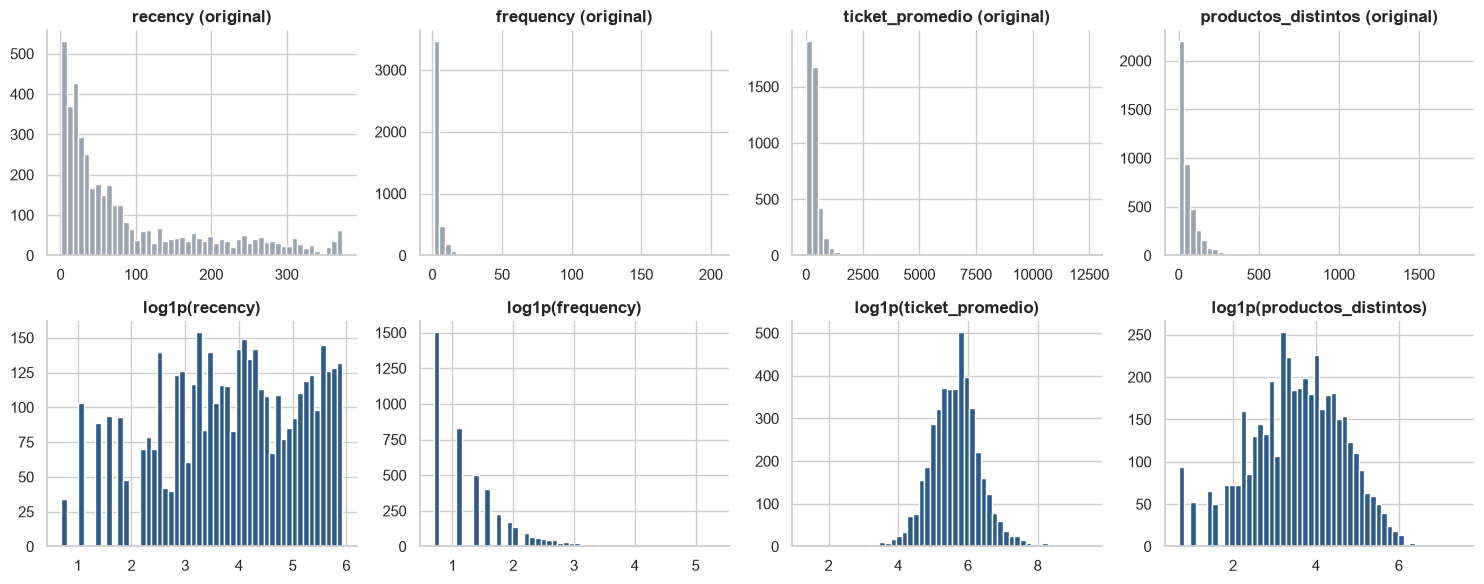

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, var in enumerate(VARIABLES_CLUSTERING):
    axes[0, j].hist(clientes[var], bins=50, color=COLOR_NEUTRO)
    axes[0, j].set_title(f"{var} (original)")
    axes[1, j].hist(np.log1p(clientes[var]), bins=50, color=COLOR_PRINCIPAL)
    axes[1, j].set_title(f"log1p({var})")
fig.tight_layout()
guardar_figura(fig, "02_log1p")
plt.show()

**Hallazgos — asimetría**

- `log1p` deja las cuatro variables de clustering casi simétricas: la asimetría pasa de 1,24 a −0,33 en recency,
  de 11,84 a 1,22 en frequency, de 10,04 a 0,00 en ticket y de 6,83 a −0,25 en productos.
- `frequency` sigue algo sesgada (1,22) porque es discreta y el 34,8 % vale 1. Ninguna transformación monótona
  puede repartir un valor que comparten tantos clientes.
- `tasa_devoluciones` apenas mejora (10,45 → 8,72): con un 73,5 % de ceros, el log no la normaliza.
- Se usa `log1p` (log(1 + x)) en lugar de `log` porque está definida en 0 y es casi igual a log para valores grandes.